# 00. 시작하기 — ROS2 자율주행 실습 환경 준비

**H-Mobility 자율주행 심화과정 · 성균관대학교 Automation Lab.**

이 실습 시리즈는 `ros3_ws` 프로젝트의 **실제 소스 코드**(`func_lib`)를 그대로 불러와,
ROS2나 하드웨어 없이 **샘플 이미지·가상 데이터만으로** 자율주행 알고리즘을 체험합니다.

## 전체 파이프라인
```
[인지 Perception]                 [판단 Decision]        [제어 Control]
카메라 → 차선/신호등 검출  ─┐
라이다 → 장애물 감지       ─┼─▶ motion_planner ─▶ 시리얼 ─▶ Arduino(모터/조향)
                            └▶ path_planner(경로) ┘
```

## 실습 목차
| 노트북 | 주제 | 사용하는 실제 코드 |
|--------|------|-------------------|
| 00 | 환경 준비 (현재) | — |
| 01 | 카메라 인지 (차선·신호등) | `camera_perception_func_lib.py` |
| 02 | 판단·경로계획 | `path_planner_node.py`, `decision_making_function_lib.py` |
| 03 | 라이다 인지 | `lidar_perception_func_lib.py` |
| 04 | 시리얼·통합 | `protocol_convert_func_lib.py`, `motion_planner_node.py` |

각 노트북은 **개념 설명 → 실제 코드 실행 → 🎯 미션(직접 수정)** 순서로 구성됩니다.


## 1) 필요한 라이브러리 확인
실습에 필요한 패키지가 설치되어 있는지 확인합니다.


In [1]:
import importlib
need = ['cv2', 'numpy', 'scipy', 'matplotlib']
for m in need:
    try:
        mod = importlib.import_module(m)
        print(f'  [OK] {m:12s}', getattr(mod, '__version__', ''))
    except ImportError:
        print(f'  [빠짐] {m}  ->  pip install {m} 필요')


  [OK] cv2          5.0.0
  [OK] numpy        2.4.6
  [OK] scipy        1.17.1
  [OK] matplotlib   3.11.1


## 공통 설정 실행
아래 셀은 **모든 노트북 맨 위에서 한 번 실행**합니다. 프로젝트 루트를 찾고, 실제 코드가 있는 `lib` 폴더들을 import 경로에 등록하며, 이미지 표시 헬퍼(`show`, `show_row`)를 정의합니다.


In [2]:
# === 공통 설정: 프로젝트 루트 찾기 + 라이브러리 경로 등록 ===
import sys, math
from pathlib import Path
import numpy as np
import cv2
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.font_manager as _fm

# 그래프 한글 라벨이 깨지지 않도록 한글 폰트 지정 (Windows=맑은고딕 / Linux=나눔고딕)
for _f in [r'C:\Windows\Fonts\malgun.ttf', '/usr/share/fonts/truetype/nanum/NanumGothic.ttf']:
    try:
        _fm.fontManager.addfont(_f)
        matplotlib.rcParams['font.family'] = _fm.FontProperties(fname=_f).get_name()
        break
    except Exception:
        pass
matplotlib.rcParams['axes.unicode_minus'] = False

def find_root(start):
    p = Path(start).resolve()
    for cand in [p, *p.parents]:
        if (cand / 'src' / 'camera_perception_pkg').exists():
            return cand
    raise RuntimeError('ros3_ws 루트를 찾지 못했습니다. 노트북을 education_notebooks/ 안에서 실행하세요.')

ROOT = find_root(Path.cwd())
print('프로젝트 루트:', ROOT)

# 각 패키지의 lib 경로를 import 경로에 등록
CAM_LIB   = ROOT/'src'/'camera_perception_pkg'/'camera_perception_pkg'/'lib'
LIDAR_LIB = ROOT/'src'/'lidar_perception_pkg'/'lidar_perception_pkg'/'lib'
DEC_LIB   = ROOT/'src'/'decision_making_pkg'/'decision_making_pkg'/'lib'
SER_LIB   = ROOT/'src'/'serial_communication_pkg'/'serial_communication_pkg'/'lib'
SAMPLES   = CAM_LIB/'Collected_Datasets'/'sample_dataset'
for p in (CAM_LIB, LIDAR_LIB, DEC_LIB, SER_LIB):
    sys.path.insert(0, str(p))

# Jupyter/터미널 어디서든 이미지를 인라인으로 보기 위한 헬퍼
def show(img, title='', cmap=None, figsize=(6,4)):
    plt.figure(figsize=figsize)
    if img.ndim == 3:
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))   # OpenCV는 BGR, matplotlib은 RGB
    else:
        plt.imshow(img, cmap=cmap or 'gray')
    plt.title(title); plt.axis('off'); plt.tight_layout(); plt.show()

def show_row(imgs, titles=None, cmap=None, figsize=(14,4)):
    n = len(imgs); titles = titles or ['']*n
    plt.figure(figsize=figsize)
    for i,(im,t) in enumerate(zip(imgs, titles)):
        ax = plt.subplot(1, n, i+1)
        if im.ndim == 3: ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        else: ax.imshow(im, cmap=cmap or 'gray')
        ax.set_title(t); ax.axis('off')
    plt.tight_layout(); plt.show()

print('OpenCV', cv2.__version__, '| NumPy', np.__version__)


프로젝트 루트: C:\Users\asus\Documents\workspace\ros3_ws
OpenCV 5.0.0 | NumPy 2.4.6


## 2) 샘플 데이터 확인
프로젝트에 포함된 주행 샘플 이미지 12장을 확인합니다.


In [3]:
sample_files = sorted(SAMPLES.glob('*'))
print(f'샘플 이미지 {len(sample_files)}장:')
for f in sample_files:
    print('  -', f.name)

# 첫 이미지 한 장 불러와 크기 확인
img = cv2.imread(str(sample_files[0]))
print('\n예시 이미지 shape (H, W, C):', img.shape)


샘플 이미지 12장:
  - sample01.png
  - sample02.png
  - sample03.png
  - sample04.png
  - sample05.jpg
  - sample06.jpg
  - sample07.jpg
  - sample08.jpg
  - sample09.jpg
  - sample10.png
  - sample11.png
  - sample12.jpg

예시 이미지 shape (H, W, C): (480, 640, 3)


## 3) 샘플 이미지 미리보기
소형 자율주행 트랙(흰 차선 · 초록 신호등 · 횡단보도)이 촬영된 이미지입니다.


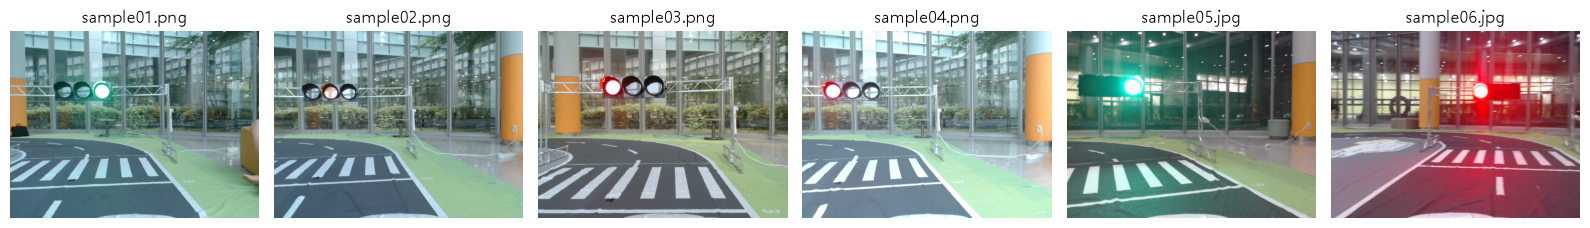

In [4]:
imgs = [cv2.imread(str(f)) for f in sample_files[:6]]
show_row(imgs, [f.name for f in sample_files[:6]], figsize=(16,5))


## 4) 실습 방법 안내
- 각 셀을 위에서부터 순서대로 **Shift+Enter** 로 실행하세요.
- 🎯 **미션** 셀에는 `# TODO` 가 있습니다. 직접 값을 바꾸거나 코드를 완성해 보세요.
- 미션 아래 **▶ 정답 예시** 셀에 참고 답안이 있습니다. 먼저 스스로 해본 뒤 확인하세요.

> **참고:** Jupyter가 설치되어 있지 않다면 터미널에서 `pip install jupyter` 후
> `jupyter notebook` 으로 실행하거나, VS Code / Antigravity IDE의 노트북 기능을 사용하세요.

준비가 끝났습니다. **`01_카메라인지.ipynb`** 로 이동하세요! 🚗
